In [1]:
!pip install ultralytics


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [2]:
# ==========================================
# Import Required Libraries
# ==========================================

# Standard libraries
import os
import random
from pathlib import Path
from collections import Counter
import shutil

# Numerical computing
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Image processing
import cv2
from PIL import Image

# YOLO (Ultralytics)
from ultralytics import YOLO

# Notebook utilities
from tqdm import tqdm

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

In [3]:
# ==========================================
# Dataset Paths
# ==========================================

DATASET_PATH = "/Users/sandrakhyikwa/AI_Tech/Road-damage-detection/data/RDD_SPLIT"

TRAIN_IMAGES = os.path.join(DATASET_PATH, "train/images")
TRAIN_LABELS = os.path.join(DATASET_PATH, "train/labels")

VAL_IMAGES = os.path.join(DATASET_PATH, "val/images")
VAL_LABELS = os.path.join(DATASET_PATH, "val/labels")

TEST_IMAGES = os.path.join(DATASET_PATH, "test/images")
TEST_LABELS = os.path.join(DATASET_PATH, "test/labels")

# **Dataset Overview**

In [4]:
# ==========================================
# Dataset Overview
# ==========================================

# Count images and labels in each split
train_images = len(os.listdir(TRAIN_IMAGES))
train_labels = len(os.listdir(TRAIN_LABELS))

val_images = len(os.listdir(VAL_IMAGES))
val_labels = len(os.listdir(VAL_LABELS))

test_images = len(os.listdir(TEST_IMAGES))
test_labels = len(os.listdir(TEST_LABELS))

print(f"Train Images : {train_images}")
print(f"Train Labels : {train_labels}")

print(f"\nValidation Images : {val_images}")
print(f"Validation Labels : {val_labels}")

print(f"\nTest Images : {test_images}")
print(f"Test Labels : {test_labels}")

Train Images : 26869
Train Labels : 26869

Validation Images : 5758
Validation Labels : 5758

Test Images : 5758
Test Labels : 5758


In [5]:
# ==========================================
# Class Names
# ==========================================

class_names = [
    "Longitudinal Crack",
    "Transverse Crack",
    "Alligator Crack",
    "Other Corruption",
    "Pothole"
]

print(class_names)

['Longitudinal Crack', 'Transverse Crack', 'Alligator Crack', 'Other Corruption', 'Pothole']


In [6]:
# ==========================================
# Display Dataset Information
# ==========================================

print("=" * 50)
print("Road Damage Detection Dataset")
print("=" * 50)

print(f"Number of Classes : {len(class_names)}")
print(f"Training Images   : {train_images}")
print(f"Validation Images : {val_images}")
print(f"Test Images       : {test_images}")

print("\nClasses:")
for i, cls in enumerate(class_names):
    print(f"{i} -> {cls}")

Road Damage Detection Dataset
Number of Classes : 5
Training Images   : 26869
Validation Images : 5758
Test Images       : 5758

Classes:
0 -> Longitudinal Crack
1 -> Transverse Crack
2 -> Alligator Crack
3 -> Other Corruption
4 -> Pothole


# **EDA**

In [7]:
# ==========================================
# Analyze Class Distribution for Train
# ==========================================

# Initialize class counts
class_counts = {i: 0 for i in range(len(class_names))}

# Get all label files
label_files = os.listdir(TRAIN_LABELS)

# Count objects for each class
for label_file in tqdm(label_files):

    label_path = os.path.join(TRAIN_LABELS, label_file)

    with open(label_path, "r") as file:

        lines = file.readlines()

        for line in lines:

            class_id = int(line.split()[0])

            class_counts[class_id] += 1

num_obj = np.sum(list(class_counts.values()))

# Convert to DataFrame
class_df_train = pd.DataFrame({
    "Class": class_names,
    "Objects": list(class_counts.values()),
    'percentage': list(class_counts.values())/num_obj*100
})

class_df_train

100%|██████████| 26869/26869 [00:02<00:00, 11759.67it/s]


,Class,Objects,percentage
0,Longitudinal Crack,18201,39.314412
1,Transverse Crack,8386,18.113876
2,Alligator Crack,7527,16.258424
3,Other Corruption,7554,16.316744
4,Pothole,4628,9.996544


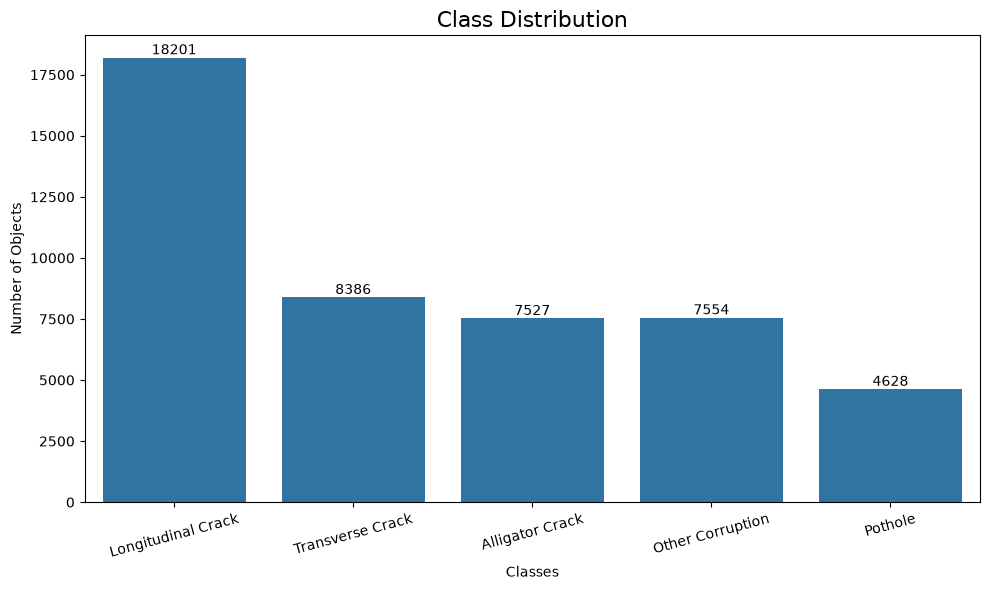

In [8]:
# ==========================================
# Plot Class Distribution
# ==========================================

plt.figure(figsize=(10,6))

bars = sns.barplot(
    x=class_df_train["Class"],
    y=class_df_train["Objects"]
)

plt.title("Class Distribution", fontsize=16)

plt.xlabel("Classes")

plt.ylabel("Number of Objects")

plt.xticks(rotation=15)

# Add values above bars
for i in bars.containers:
    bars.bar_label(i)

plt.tight_layout()

plt.show()

In [9]:
# ==========================================
# Analyze Class Distribution for Validate
# ==========================================

# Initialize class counts
class_counts = {i: 0 for i in range(len(class_names))}

# Get all label files
label_files = os.listdir(VAL_LABELS)

# Count objects for each class
for label_file in tqdm(label_files):

    label_path = os.path.join(VAL_LABELS, label_file)

    with open(label_path, "r") as file:

        lines = file.readlines()

        for line in lines:

            class_id = int(line.split()[0])

            class_counts[class_id] += 1

num_obj = np.sum(list(class_counts.values()))

# Convert to DataFrame
class_df_val = pd.DataFrame({
    "Class": class_names,
    "Objects": list(class_counts.values()),
    'percentage': list(class_counts.values())/num_obj*100
})
class_df_val

100%|██████████| 5758/5758 [00:00<00:00, 12754.52it/s]


,Class,Objects,percentage
0,Longitudinal Crack,3890,39.934298
1,Transverse Crack,1769,18.160353
2,Alligator Crack,1553,15.942922
3,Other Corruption,1564,16.055846
4,Pothole,965,9.906580


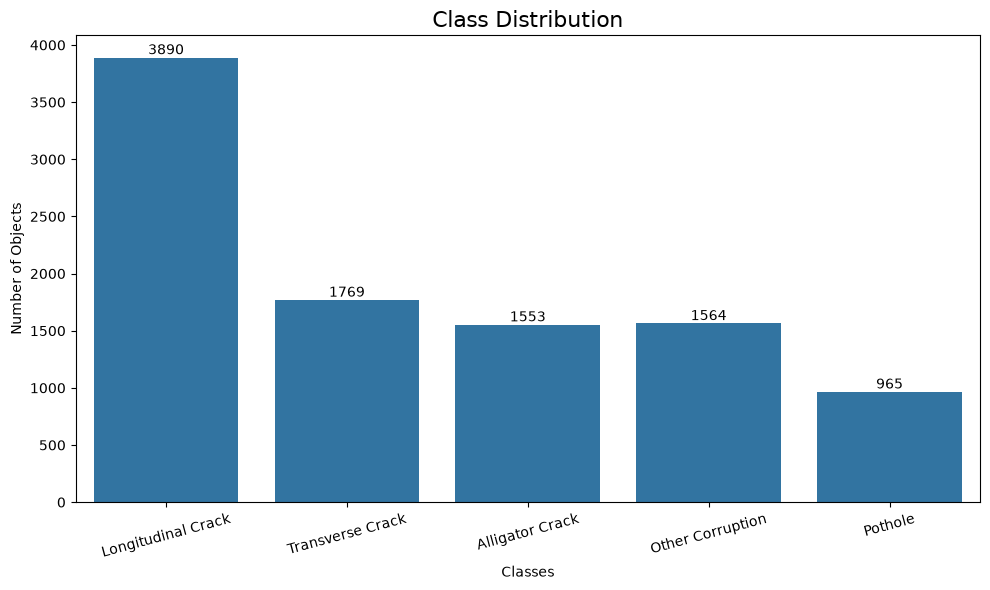

In [10]:
# ==========================================
# Plot Class Distribution
# ==========================================

plt.figure(figsize=(10,6))

bars = sns.barplot(
    x=class_df_val["Class"],
    y=class_df_val["Objects"]
)

plt.title("Class Distribution", fontsize=16)

plt.xlabel("Classes")

plt.ylabel("Number of Objects")

plt.xticks(rotation=15)

# Add values above bars
for i in bars.containers:
    bars.bar_label(i)

plt.tight_layout()

plt.show()

In [11]:
# ==========================================
# Analyze Class Distribution for Test
# ==========================================

# Initialize class counts
class_counts = {i: 0 for i in range(len(class_names))}

# Get all label files
label_files = os.listdir(TEST_LABELS)

# Count objects for each class
for label_file in tqdm(label_files):

    label_path = os.path.join(TEST_LABELS, label_file)

    with open(label_path, "r") as file:

        lines = file.readlines()

        for line in lines:

            class_id = int(line.split()[0])

            class_counts[class_id] += 1

num_obj = np.sum(list(class_counts.values()))

# Convert to DataFrame
class_df_test = pd.DataFrame({
    "Class": class_names,
    "Objects": list(class_counts.values()),
    'percentage': list(class_counts.values())/num_obj*100
})
class_df_test

100%|██████████| 5758/5758 [00:00<00:00, 12919.09it/s]


,Class,Objects,percentage
0,Longitudinal Crack,3925,40.568475
1,Transverse Crack,1675,17.312661
2,Alligator Crack,1537,15.886305
3,Other Corruption,1587,16.403101
4,Pothole,951,9.829457


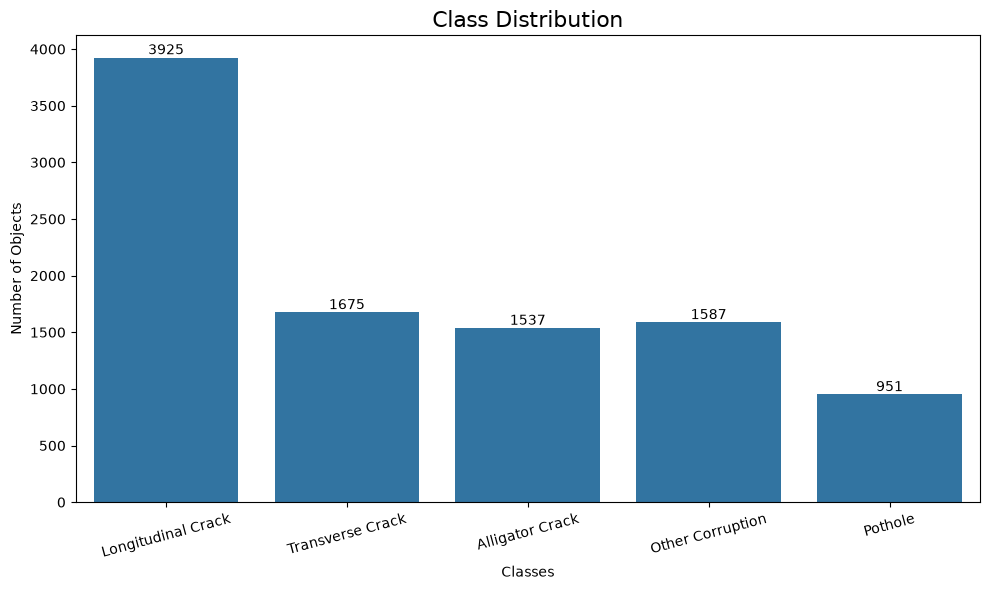

In [12]:
# ==========================================
# Plot Class Distribution
# ==========================================

plt.figure(figsize=(10,6))

bars = sns.barplot(
    x=class_df_test["Class"],
    y=class_df_test["Objects"]
)

plt.title("Class Distribution", fontsize=16)

plt.xlabel("Classes")

plt.ylabel("Number of Objects")

plt.xticks(rotation=15)

# Add values above bars
for i in bars.containers:
    bars.bar_label(i)

plt.tight_layout()

plt.show()

# Observation:
The dataset is moderately imbalanced across the five road damage classes. Longitudinal Crack is the most frequent class in all dataset splits, while Pothole has the fewest annotated objects. Despite this imbalance, the validation and test sets follow a distribution similar to the training set, indicating that the dataset was split consistently. This consistent distribution provides a reliable basis for model training and evaluation.

In [13]:
# ==========================================
# Objects per Image Analysis
# ==========================================

objects_per_image = []

for label_file in tqdm(os.listdir(TRAIN_LABELS)):

    label_path = os.path.join(TRAIN_LABELS, label_file)

    with open(label_path, "r") as f:

        num_objects = len(f.readlines())

    objects_per_image.append(num_objects)

objects_per_image = np.array(objects_per_image)

100%|██████████| 26869/26869 [00:02<00:00, 12330.84it/s]


In [14]:
# ==========================================
# Objects Statistics
# ==========================================

print(f"Total Images      : {len(objects_per_image)}")
print(f"Total Objects     : {objects_per_image.sum()}")
print(f"Average Objects   : {objects_per_image.mean():.2f}")
print(f"Median Objects    : {np.median(objects_per_image):.2f}")
print(f"Minimum Objects   : {objects_per_image.min()}")
print(f"Maximum Objects   : {objects_per_image.max()}")

Total Images      : 26869
Total Objects     : 46296
Average Objects   : 1.72
Median Objects    : 1.00
Minimum Objects   : 0
Maximum Objects   : 44


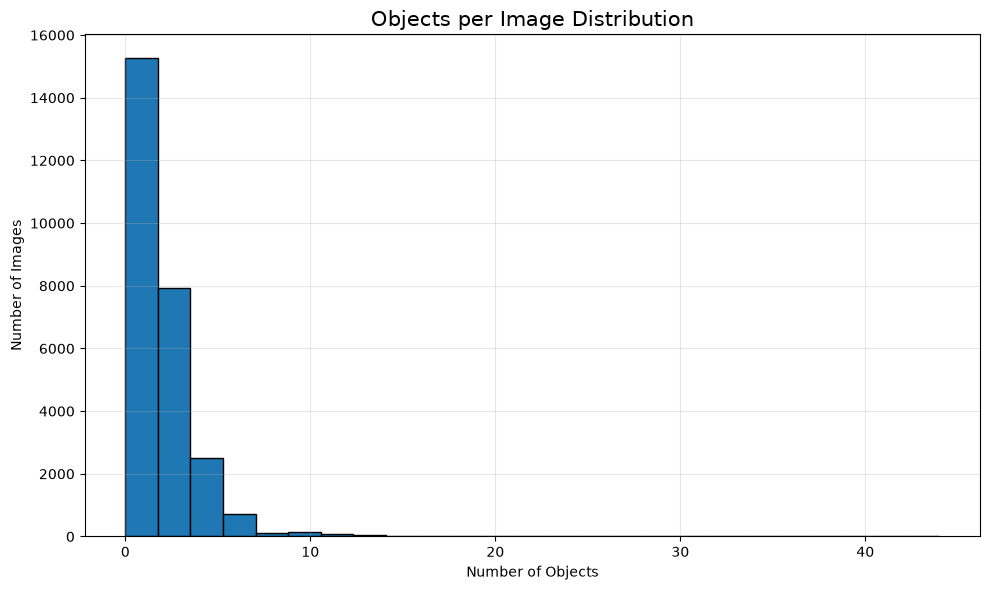

In [15]:
# ==========================================
# Plot Objects per Image
# ==========================================

plt.figure(figsize=(10,6))

plt.hist(
    objects_per_image,
    bins=25,
    edgecolor="black"
)

plt.title("Objects per Image Distribution", fontsize=15)

plt.xlabel("Number of Objects")

plt.ylabel("Number of Images")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

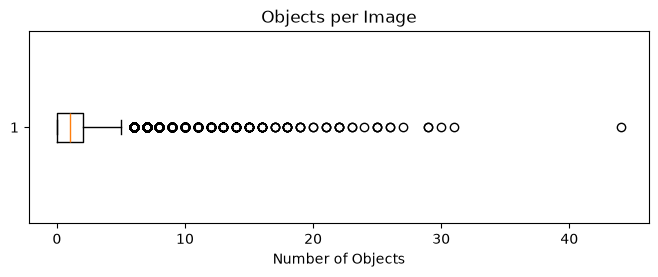

In [16]:
# ==========================================
# Objects per Image Boxplot
# ==========================================

plt.figure(figsize=(8,2.5))

plt.boxplot(
    objects_per_image,
    vert=False
)

plt.title("Objects per Image")

plt.xlabel("Number of Objects")

plt.show()

In [17]:
for i in range(45):
    print(f'{i} --> {(objects_per_image == i).sum()} counts ---> {((objects_per_image == i).sum()/len(objects_per_image)*100).round(3)}%')

0 --> 8097 counts ---> 30.135%
1 --> 7165 counts ---> 26.666%
2 --> 5006 counts ---> 18.631%
3 --> 2931 counts ---> 10.908%
4 --> 1657 counts ---> 6.167%
5 --> 856 counts ---> 3.186%
6 --> 478 counts ---> 1.779%
7 --> 247 counts ---> 0.919%
8 --> 127 counts ---> 0.473%
9 --> 78 counts ---> 0.29%
10 --> 58 counts ---> 0.216%
11 --> 40 counts ---> 0.149%
12 --> 27 counts ---> 0.1%
13 --> 19 counts ---> 0.071%
14 --> 21 counts ---> 0.078%
15 --> 14 counts ---> 0.052%
16 --> 10 counts ---> 0.037%
17 --> 4 counts ---> 0.015%
18 --> 7 counts ---> 0.026%
19 --> 4 counts ---> 0.015%
20 --> 2 counts ---> 0.007%
21 --> 3 counts ---> 0.011%
22 --> 4 counts ---> 0.015%
23 --> 2 counts ---> 0.007%
24 --> 1 counts ---> 0.004%
25 --> 3 counts ---> 0.011%
26 --> 2 counts ---> 0.007%
27 --> 1 counts ---> 0.004%
28 --> 0 counts ---> 0.0%
29 --> 2 counts ---> 0.007%
30 --> 1 counts ---> 0.004%
31 --> 1 counts ---> 0.004%
32 --> 0 counts ---> 0.0%
33 --> 0 counts ---> 0.0%
34 --> 0 counts ---> 0.0%
35 -->

# Observation:
The training set contains 26,869 labeled images with a total of 46,296 annotated road damage instances, resulting in an average of 1.72 objects per image. The median value of 1 object per image indicates that most images contain only a single road damage instance. However, a small number of images include many annotations, with the maximum reaching 44 objects, making them considerably more complex than the majority of the dataset.

# Insight:
Although most images contain only one or two damage instances, a small subset includes multiple objects. These complex scenes may be more challenging for the detection model due to object density and overlapping damage regions.

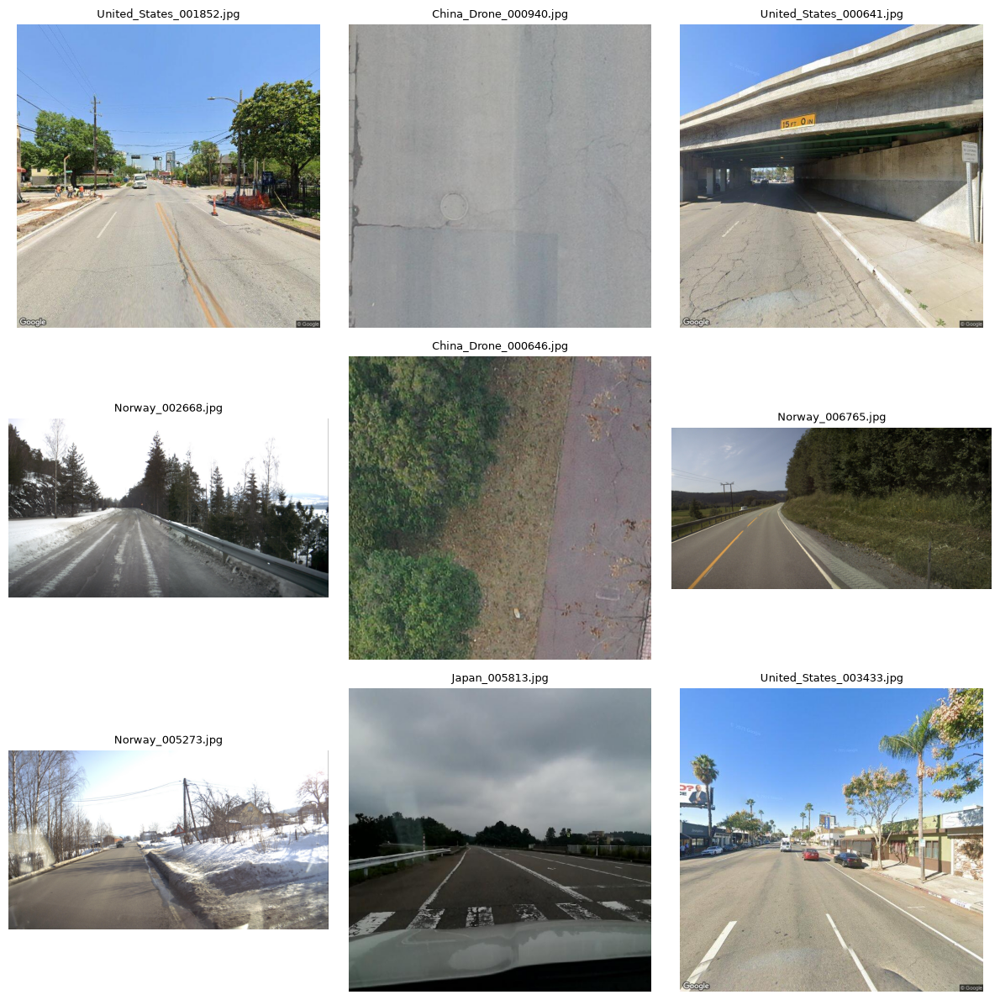

In [18]:
# ==========================================
# Display Random Training Images
# ==========================================

# Get all training images
image_files = os.listdir(TRAIN_IMAGES)

# Select random images
random_images = random.sample(image_files, 9)

plt.figure(figsize=(12, 12))

for i, image_name in enumerate(random_images):

    image_path = os.path.join(TRAIN_IMAGES, image_name)

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(image_name, fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
# ==========================================
# Draw YOLO Bounding Boxes
# ==========================================

def draw_yolo_boxes(image, label_path, class_names):

    image = image.copy()

    h, w = image.shape[:2]

    if not os.path.exists(label_path):
        return image

    with open(label_path, "r") as file:

        for line in file.readlines():

            class_id, x, y, bw, bh = map(float, line.split())

            class_id = int(class_id)

            # Convert YOLO format to pixel coordinates
            x1 = int((x - bw / 2) * w)
            y1 = int((y - bh / 2) * h)

            x2 = int((x + bw / 2) * w)
            y2 = int((y + bh / 2) * h)

            # Draw rectangle
            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

            # Draw class name
            cv2.putText(
                image,
                class_names[class_id],
                (x1+10,y1+10),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (255, 0, 0),
                2
            )

    return image

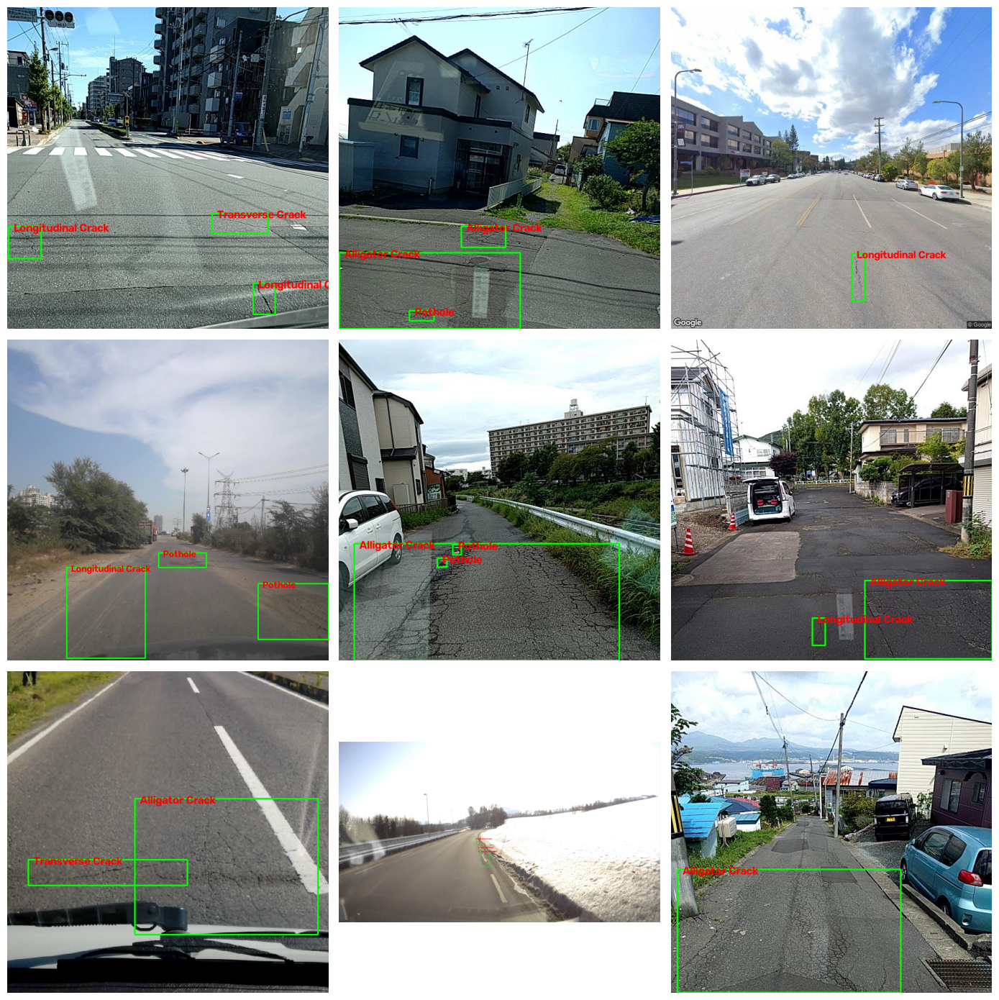

In [20]:
# ==========================================
# Display Random Images with Bounding Boxes
# ==========================================

random_images = random.sample(image_files, 9)

plt.figure(figsize=(14, 14))

for i, image_name in enumerate(random_images):

    image_path = os.path.join(TRAIN_IMAGES, image_name)

    label_name = image_name.replace(".jpg", ".txt")
    label_path = os.path.join(TRAIN_LABELS, label_name)

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    image = draw_yolo_boxes(
        image,
        label_path,
        class_names
    )

    plt.subplot(3,3,i+1)

    plt.imshow(image)

    plt.axis("off")

plt.tight_layout()

plt.show()

# Observation:
The visual inspection confirms that the bounding boxes are correctly aligned with the road damage regions. The dataset contains a wide variety of damage types, object sizes, and road conditions, making it suitable for training robust object detection models.

In [21]:
# ==========================================
# Image Resolution Analysis
# ==========================================

image_widths = []
image_heights = []

sample_images = random.sample(os.listdir(TRAIN_IMAGES), 5000)

for image_name in tqdm(sample_images):

    image_path = os.path.join(TRAIN_IMAGES, image_name)

    with Image.open(image_path) as img:
        width, height = img.size

    image_widths.append(width)
    image_heights.append(height)

100%|██████████| 5000/5000 [00:01<00:00, 4773.37it/s]


In [22]:
# ==========================================
# Image Resolution Statistics
# ==========================================

print(f"Total Images : {len(image_widths)}\n")

print(f"Minimum Width  : {min(image_widths)}")
print(f"Maximum Width  : {max(image_widths)}")
print(f"Average Width  : {np.mean(image_widths):.2f}")

print()

print(f"Minimum Height : {min(image_heights)}")
print(f"Maximum Height : {max(image_heights)}")
print(f"Average Height : {np.mean(image_heights):.2f}")

Total Images : 5000

Minimum Width  : 512
Maximum Width  : 4040
Average Width  : 1329.41

Minimum Height : 512
Maximum Height : 2044
Average Height : 934.61


In [23]:
# ==========================================
# Unique Image Resolutions
# ==========================================

resolution_df = pd.DataFrame({
    "Width": image_widths,
    "Height": image_heights
})

resolution_df["Resolution"] = (
    resolution_df["Width"].astype(str)
    + " × " +
    resolution_df["Height"].astype(str)
)

resolution_df["Resolution"].value_counts()

Resolution
600 × 600      1666
720 × 720      1009
640 × 640       612
512 × 512       581
4040 × 2035     568
3643 × 2041     392
3650 × 2044     129
1024 × 1024      22
540 × 540        13
1080 × 1080       8
Name: count, dtype: int64

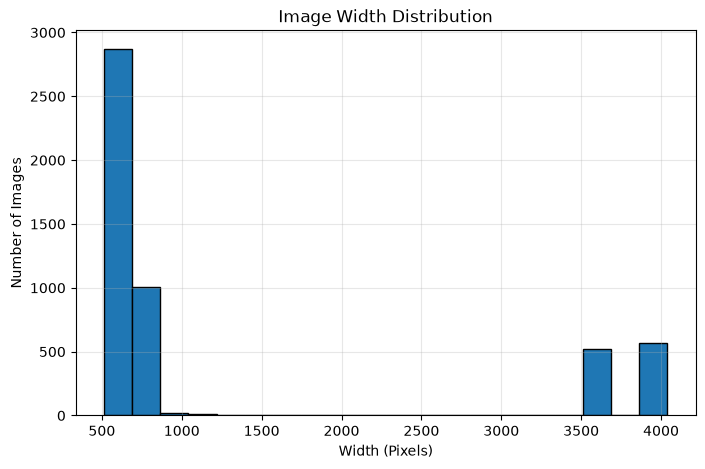

In [24]:
# ==========================================
# Width Distribution
# ==========================================

plt.figure(figsize=(8,5))

plt.hist(
    image_widths,
    bins=20,
    edgecolor="black"
)

plt.title("Image Width Distribution")

plt.xlabel("Width (Pixels)")

plt.ylabel("Number of Images")

plt.grid(alpha=0.3)

plt.show()

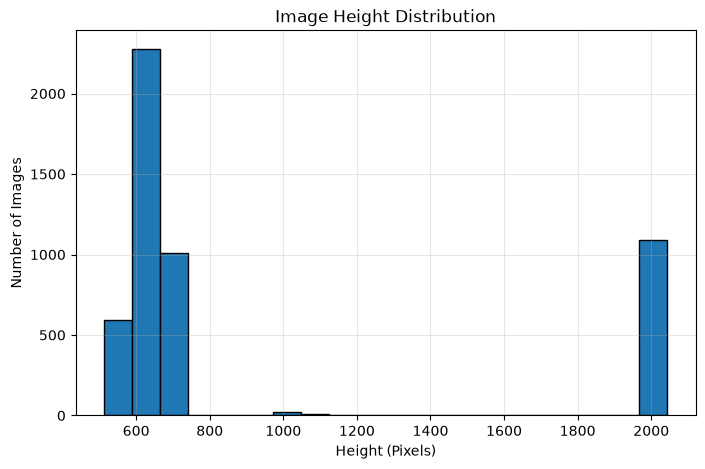

In [25]:
# ==========================================
# Height Distribution
# ==========================================

plt.figure(figsize=(8,5))

plt.hist(
    image_heights,
    bins=20,
    edgecolor="black"
)

plt.title("Image Height Distribution")

plt.xlabel("Height (Pixels)")

plt.ylabel("Number of Images")

plt.grid(alpha=0.3)

plt.show()

# Observation:
A random sample of 5,000 training images was analyzed to examine the image resolutions. The dataset contains multiple image sizes, ranging from 512 × 512 to 4040 × 2035 pixels. Most images belong to a few common resolutions, particularly 600 × 600, 720 × 720, and 640 × 640, while high-resolution images (e.g., 4040 × 2035) are less frequent. This variation indicates that the dataset was collected from different cameras and devices. During training, YOLO automatically resizes all images to the selected input size, ensuring a consistent input format for the model.

In [26]:
# ==========================================
# Missing Labels Check
# ==========================================

image_files = {
    os.path.splitext(file)[0]
    for file in os.listdir(TRAIN_IMAGES)
}

label_files = {
    os.path.splitext(file)[0]
    for file in os.listdir(TRAIN_LABELS)
}

missing_labels = image_files - label_files
missing_images = label_files - image_files

print("=" * 50)
print("Missing Labels Check")
print("=" * 50)

print(f"Images without labels : {len(missing_labels)}")
print(f"Labels without images : {len(missing_images)}")

Missing Labels Check
Images without labels : 0
Labels without images : 0


# **Choose sample of data**

In [27]:
# ==========================================
# Build Image Metadata
# ==========================================

records = []

for label_file in os.listdir(TRAIN_LABELS):

    label_path = os.path.join(TRAIN_LABELS, label_file)

    classes = []

    with open(label_path, "r") as f:

        for line in f.readlines():

            class_id = int(line.split()[0])

            classes.append(class_id)

    records.append({

        "image": label_file.replace(".txt", ".jpg"),

        "label": label_file,

        "num_objects": len(classes),

        "classes": classes

    })

train_df = pd.DataFrame(records)

train_df.head()

,image,label,num_objects,classes
0,Czech_001919.jpg,Czech_001919.txt,0,[]
1,Japan_006903.jpg,Japan_006903.txt,4,"[2, 1, 1, 1]"
2,United_States_000150.jpg,United_States_000150.txt,2,"[0, 0]"
3,China_MotorBike_001471.jpg,China_MotorBike_001471.txt,1,[0]
4,Norway_004241.jpg,Norway_004241.txt,7,"[0, 2, 0, 0, 0, 0, 0]"


In [28]:
# ==========================================
# Build Image Metadata
# ==========================================
records = []

for label_file in os.listdir(VAL_LABELS):

    label_path = os.path.join(VAL_LABELS, label_file)

    classes = []

    with open(label_path, "r") as f:

        for line in f.readlines():

            class_id = int(line.split()[0])

            classes.append(class_id)

    records.append({

        "image": label_file.replace(".txt", ".jpg"),

        "label": label_file,

        "num_objects": len(classes),

        "classes": classes

    })

val_df = pd.DataFrame(records)

val_df.head()

,image,label,num_objects,classes
0,Norway_002630.jpg,Norway_002630.txt,1,[0]
1,Norway_007990.jpg,Norway_007990.txt,0,[]
2,United_States_004336.jpg,United_States_004336.txt,2,"[4, 0]"
3,Norway_006330.jpg,Norway_006330.txt,2,"[0, 1]"
4,Norway_004527.jpg,Norway_004527.txt,2,"[1, 0]"


In [29]:
# ==========================================
# Build Image Metadata
# ==========================================

records = []

for label_file in os.listdir(TEST_LABELS):

    label_path = os.path.join(TEST_LABELS, label_file)

    classes = []

    with open(label_path, "r") as f:

        for line in f.readlines():

            class_id = int(line.split()[0])

            classes.append(class_id)

    records.append({

        "image": label_file.replace(".txt", ".jpg"),

        "label": label_file,

        "num_objects": len(classes),

        "classes": classes

    })

test_df = pd.DataFrame(records)

test_df.head()

,image,label,num_objects,classes
0,Norway_001339.jpg,Norway_001339.txt,7,"[1, 1, 1, 0, 1, 1, 0]"
1,China_MotorBike_001303.jpg,China_MotorBike_001303.txt,4,"[0, 1, 2, 0]"
2,United_States_000622.jpg,United_States_000622.txt,2,"[0, 0]"
3,Japan_012962.jpg,Japan_012962.txt,1,[3]
4,Norway_004255.jpg,Norway_004255.txt,1,[0]


In [30]:
def calculate_class_distribution(df):

    counter = Counter()

    for classes in df["classes"]:
        counter.update(classes)

    total = sum(counter.values())

    distribution = pd.DataFrame({
        "Class": list(counter.keys()),
        "Objects": list(counter.values())
    })

    distribution["Percentage"] = (
        distribution["Objects"] / total * 100
    )

    return distribution.sort_values("Class").reset_index(drop=True)

In [31]:
train_sample = train_df.sample(
    n=5000,
    random_state=42
)

train_sample_distribution = calculate_class_distribution(train_sample)

train_sample_distribution

,Class,Objects,Percentage
0,0,3308,38.708168
1,1,1554,18.183946
2,2,1392,16.288322
3,3,1420,16.615961
4,4,872,10.203604


In [32]:
class_df_train

,Class,Objects,percentage
0,Longitudinal Crack,18201,39.314412
1,Transverse Crack,8386,18.113876
2,Alligator Crack,7527,16.258424
3,Other Corruption,7554,16.316744
4,Pothole,4628,9.996544


In [33]:
val_sample = val_df.sample(
    n=2000,
    random_state=42
)

val_sample_distribution = calculate_class_distribution(val_sample)

val_sample_distribution

,Class,Objects,Percentage
0,0,1261,38.621746
1,1,619,18.958652
2,2,547,16.753446
3,3,546,16.722818
4,4,292,8.943338


In [34]:
class_df_val

,Class,Objects,percentage
0,Longitudinal Crack,3890,39.934298
1,Transverse Crack,1769,18.160353
2,Alligator Crack,1553,15.942922
3,Other Corruption,1564,16.055846
4,Pothole,965,9.906580


In [35]:
test_sample = test_df.sample(
    n=2000,
    random_state=42
)

test_sample_distribution = calculate_class_distribution(test_sample)

test_sample_distribution

,Class,Objects,Percentage
0,0,1354,42.010549
1,1,575,17.840521
2,2,503,15.606578
3,3,509,15.792740
4,4,282,8.749612


In [36]:
class_df_test

,Class,Objects,percentage
0,Longitudinal Crack,3925,40.568475
1,Transverse Crack,1675,17.312661
2,Alligator Crack,1537,15.886305
3,Other Corruption,1587,16.403101
4,Pothole,951,9.829457


# Observation:
A random subset of the training dataset was selected using a fixed random seed (random_state=42). After comparing the class distribution between the original dataset and the sampled dataset, the differences across all classes were found to be less than 0.5%, indicating that the sampled dataset preserves the original class distribution and can be considered representative for model training and evaluation.

In [37]:
# ==========================================
# Create RDD_SAMPLE Directory Structure
# ==========================================

import os

BASE_SAMPLE_DIR = "/Users/sandrakhyikwa/AI_Tech/Road-damage-detection/data/dataset/RDD_SAMPLE"

splits = ["train", "val", "test"]
folders = ["images", "labels"]

for split in splits:
    for folder in folders:

        os.makedirs(
            os.path.join(BASE_SAMPLE_DIR, split, folder),
            exist_ok=True
        )

print("RDD_SAMPLE directory created successfully!")

RDD_SAMPLE directory created successfully!


In [38]:
# ==========================================
# Copy Sample Dataset
# ==========================================

def copy_sample(df,
                source_images,
                source_labels,
                destination):

    for _, row in tqdm(df.iterrows(), total=len(df)):

        # Image
        shutil.copy2(
            os.path.join(source_images, row["image"]),
            os.path.join(destination, "images", row["image"])
        )

        # Label
        shutil.copy2(
            os.path.join(source_labels, row["label"]),
            os.path.join(destination, "labels", row["label"])
        )

In [39]:
copy_sample(
    train_sample,
    TRAIN_IMAGES,
    TRAIN_LABELS,
    os.path.join(BASE_SAMPLE_DIR, "train")
)

100%|██████████| 5000/5000 [00:07<00:00, 656.55it/s]


In [40]:
copy_sample(
    val_sample,
    VAL_IMAGES,
    VAL_LABELS,
    os.path.join(BASE_SAMPLE_DIR, "val")
)

100%|██████████| 2000/2000 [00:03<00:00, 643.79it/s]


In [41]:
copy_sample(
    test_sample,
    TEST_IMAGES,
    TEST_LABELS,
    os.path.join(BASE_SAMPLE_DIR, "test")
)

100%|██████████| 2000/2000 [00:02<00:00, 689.96it/s]


In [42]:
# ==========================================
# Verify Sample Dataset
# ==========================================

for split in splits:

    image_count = len(os.listdir(os.path.join(BASE_SAMPLE_DIR, split, "images")))

    label_count = len(os.listdir(os.path.join(BASE_SAMPLE_DIR, split, "labels")))

    print(f"{split.upper()}")

    print(f"Images : {image_count}")

    print(f"Labels : {label_count}")

    print("-"*30)

TRAIN
Images : 5000
Labels : 5000
------------------------------
VAL
Images : 2000
Labels : 2000
------------------------------
TEST
Images : 2000
Labels : 2000
------------------------------


# **Create data.yaml**

In [47]:
# ==========================================
# Create data.yaml
# ==========================================

data_yaml = """

train: /Users/sandrakhyikwa/AI_Tech/Road-damage-detection/data/dataset/RDD_SAMPLE/train/images
val: /Users/sandrakhyikwa/AI_Tech/Road-damage-detection/data/dataset/RDD_SAMPLE/val/images
test: /Users/sandrakhyikwa/AI_Tech/Road-damage-detection/data/dataset/RDD_SAMPLE/test/images

nc: 5

names:
  0: Longitudinal Crack
  1: Transverse Crack
  2: Alligator Crack
  3: Other Corruption
  4: Pothole
"""

with open("data.yaml", "w") as f:
    f.write(data_yaml)

print("data.yaml created successfully!")

data.yaml created successfully!


In [48]:
with open('/Users/sandrakhyikwa/AI_Tech/Road-damage-detection/notebook/data.yaml','r') as y:
    print(y.read())




train: /Users/sandrakhyikwa/AI_Tech/Road-damage-detection/data/dataset/RDD_SAMPLE/train/images
val: /Users/sandrakhyikwa/AI_Tech/Road-damage-detection/data/dataset/RDD_SAMPLE/val/images
test: /Users/sandrakhyikwa/AI_Tech/Road-damage-detection/data/dataset/RDD_SAMPLE/test/images

nc: 5

names:
  0: Longitudinal Crack
  1: Transverse Crack
  2: Alligator Crack
  3: Other Corruption
  4: Pothole



# **Train YOLOv8 Nano**

In [49]:
# ==========================================
# Load YOLOv8 Nano Model
# ==========================================

from ultralytics import YOLO

model_nano = YOLO("yolov8n.pt")

In [52]:
# ==========================================
# Train YOLOv8 Nano Model
# ==========================================
PROJECT_ROOT = "/Users/sandrakhyikwa/AI_Tech/Road-damage-detection"
results_nano = model_nano.train(

    data=f"{PROJECT_ROOT}/notebook/data.yaml",

    epochs=50,

    imgsz=640,

    batch=16,

    patience=20,

    seed=42,

    project=f"{PROJECT_ROOT}/reports/runs/detect",

    name="YOLOv8n",
    
    exist_ok=True,
    
    device="mps",

)

Ultralytics 8.4.177 🚀 Python-3.14.0 torch-2.14.1 MPS (Apple M4)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/sandrakhyikwa/AI_Tech/Road-damage-detection/notebook/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLOv8n, nbs=64, nms=None, opset=None,

In [53]:
# ==========================================
# Read Training Results
# ==========================================

results = pd.read_csv(
    "/Users/sandrakhyikwa/AI_Tech/Road-damage-detection/reports/runs/detect/YOLOv8n/results.csv"
)

results

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,241.892,2.19388,4.56501,1.95762,0.24655,0.15715,0.10191,0.03993,2.33036,3.77496,2.04102,0.000369,0.000369,0.000369
1,2,491.346,2.20295,3.09932,1.94209,0.17902,0.14365,0.08263,0.03267,2.49205,3.68982,2.21964,0.000725,0.000725,0.000725
2,3,731.644,2.20649,3.03313,1.96469,0.18797,0.21010,0.11141,0.03919,2.36669,4.18610,2.02868,0.001066,0.001066,0.001066
3,4,964.267,2.16580,2.93478,1.91522,0.23889,0.19181,0.13959,0.05815,2.31558,3.43120,2.00562,0.001045,0.001045,0.001045
4,5,1193.790,2.10871,2.80251,1.88111,0.23999,0.23339,0.14553,0.05525,2.24699,3.21938,1.97171,0.001023,0.001023,0.001023
5,6,1421.400,2.07012,2.71254,1.83527,0.27774,0.25517,0.18566,0.07647,2.17675,2.99583,1.91180,0.001001,0.001001,0.001001
6,7,1651.590,2.02237,2.67574,1.80443,0.27930,0.25349,0.18356,0.07733,2.15768,3.31806,1.89832,0.000979,0.000979,0.000979
7,8,1875.770,2.01088,2.60208,1.78509,0.31612,0.27015,0.21505,0.08926,2.12441,2.84182,1.85967,0.000957,0.000957,0.000957
8,9,2109.650,1.98798,2.56308,1.76522,0.32240,0.26949,0.20771,0.08961,2.08378,2.90657,1.85424,0.000935,0.000935,0.000935
9,10,2329.540,1.95562,2.48260,1.73434,0.31066,0.28816,0.23811,0.10325,2.12767,2.93692,1.84306,0.000913,0.000913,0.000913


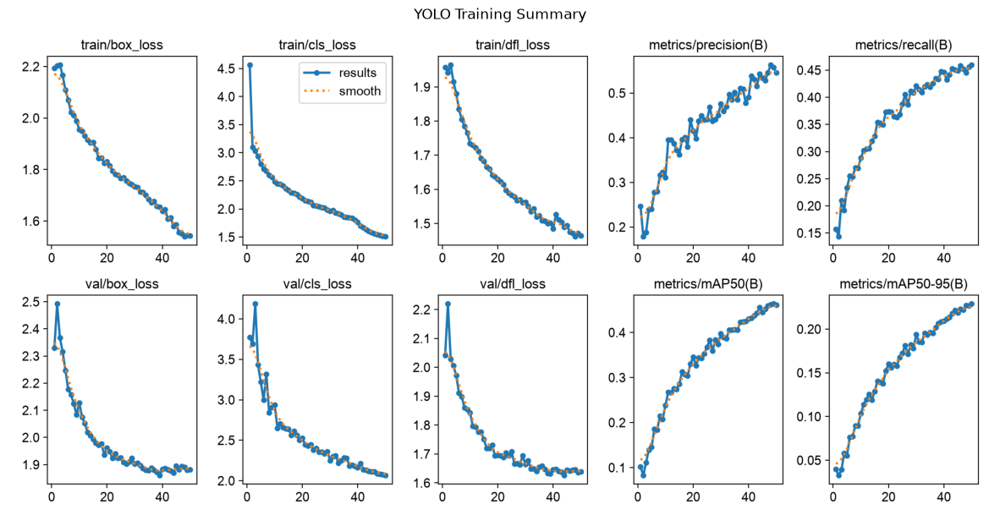

In [54]:
img_path = '/Users/sandrakhyikwa/AI_Tech/Road-damage-detection/reports/runs/detect/YOLOv8n/results.png'
img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(15,8))
plt.imshow(img)
plt.axis("off")
plt.title("YOLO Training Summary")
plt.show()

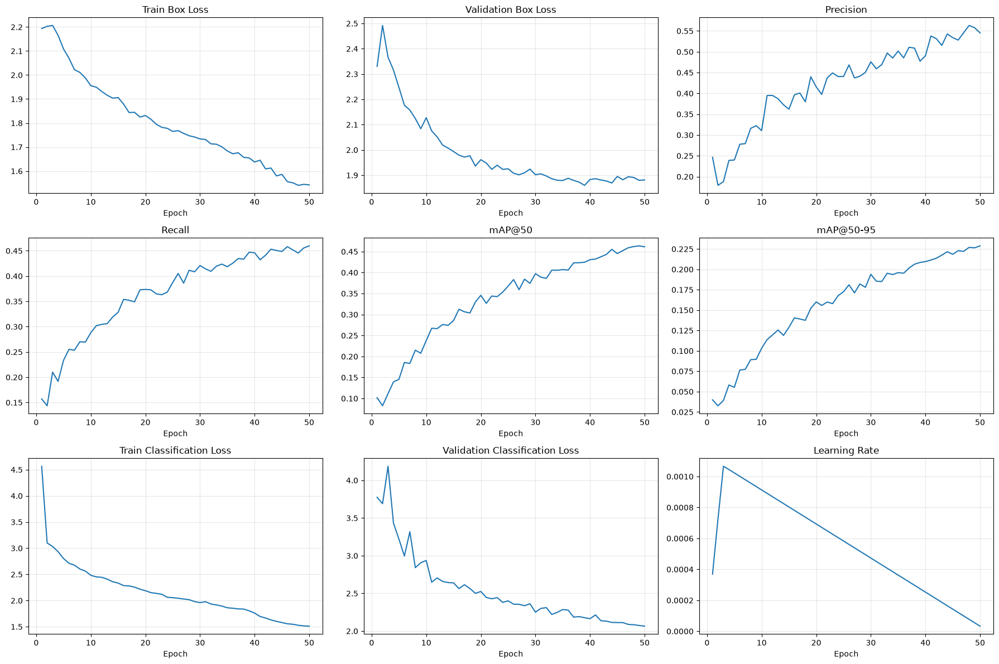

In [55]:
# ==========================================
# Visualize Training Results
# ==========================================

metrics = [

    ("train/box_loss", "Train Box Loss"),

    ("val/box_loss", "Validation Box Loss"),

    ("metrics/precision(B)", "Precision"),

    ("metrics/recall(B)", "Recall"),

    ("metrics/mAP50(B)", "mAP@50"),

    ("metrics/mAP50-95(B)", "mAP@50-95"),

    ("train/cls_loss", "Train Classification Loss"),

    ("val/cls_loss", "Validation Classification Loss"),

    ("lr/pg0", "Learning Rate")

]

plt.figure(figsize=(18, 12))

for i, (column, title) in enumerate(metrics):

    plt.subplot(3, 3, i + 1)

    plt.plot(results["epoch"], results[column])

    plt.title(title)

    plt.xlabel("Epoch")

    plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [57]:
best_model_nano = YOLO(
    "/Users/sandrakhyikwa/AI_Tech/Road-damage-detection/reports/runs/detect/YOLOv8n/weights/best.pt"
)

# ==========================================
# Evaluate YOLOv8 Nano Model
# ==========================================

metrics_nano = best_model_nano.val(
    data=f"{PROJECT_ROOT}/notebook/data.yaml",
    project=f"{PROJECT_ROOT}/reports/runs/detect",
    split="test"
)

Ultralytics 8.4.177 🚀 Python-3.14.0 torch-2.14.1 CPU (Apple M4)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1930.1±1109.6 MB/s, size: 398.6 KB)
val: Scanning /Users/sandrakhyikwa/AI_Tech/Road-damage-detection/data/dataset/RDD_SAMPLE/test/labels.cache... 2000 images, 631 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2000/2000 2.1Git/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 2.2it/s 56.0s0.4ss
                   all       2000       3223      0.516      0.455      0.453       0.22
    Longitudinal Crack        724       1354       0.55      0.435      0.446       0.22
      Transverse Crack        373        575      0.495      0.412      0.402      0.163
       Alligator Crack        397        503       0.56      0.545      0.549      0.263
      Other Corruption        355        509      0.567      0.613      0.597      0.3

In [58]:
# ==========================================
# Extract Evaluation Metrics
# ==========================================

nano_results = {

    "Model": "YOLOv8n",

    "Precision": metrics_nano.box.mp,

    "Recall": metrics_nano.box.mr,

    "mAP50": metrics_nano.box.map50,

    "mAP50-95": metrics_nano.box.map,

    "FPS": None,

    "Inference Time (ms)": None,

    "Model Size (MB)": round(
        os.path.getsize(
            f"{PROJECT_ROOT}/reports/runs/detect/YOLOv8n/weights/best.pt"
        ) / (1024 ** 2),
        2
    )
}

nano_results

{'Model': 'YOLOv8n',
 'Precision': np.float64(0.5163678078697072),
 'Recall': np.float64(0.4547590933235342),
 'mAP50': np.float64(0.4525910053220742),
 'mAP50-95': np.float64(0.21977625266425435),
 'FPS': None,
 'Inference Time (ms)': None,
 'Model Size (MB)': 6.21}

In [59]:
# ==========================================
# Select Random Test Images
# ==========================================

sample_images = np.random.choice(
    os.listdir(TEST_IMAGES),
    9
)

sample_images

array(['India_003825.jpg', 'India_008966.jpg', 'Japan_001548.jpg', 'India_007293.jpg', 'Norway_006006.jpg', 'Norway_005200.jpg', 'United_States_003466.jpg', 'Japan_010469.jpg', 'India_004046.jpg'], dtype='<U26')

In [60]:
sources=[
        os.path.join(TEST_IMAGES, image)
        for image in sample_images]


In [61]:
# ==========================================
# Predict on Test Images
# ==========================================

results = best_model_nano.predict(

    source=sources,

    conf=0.25,

    verbose=False
)

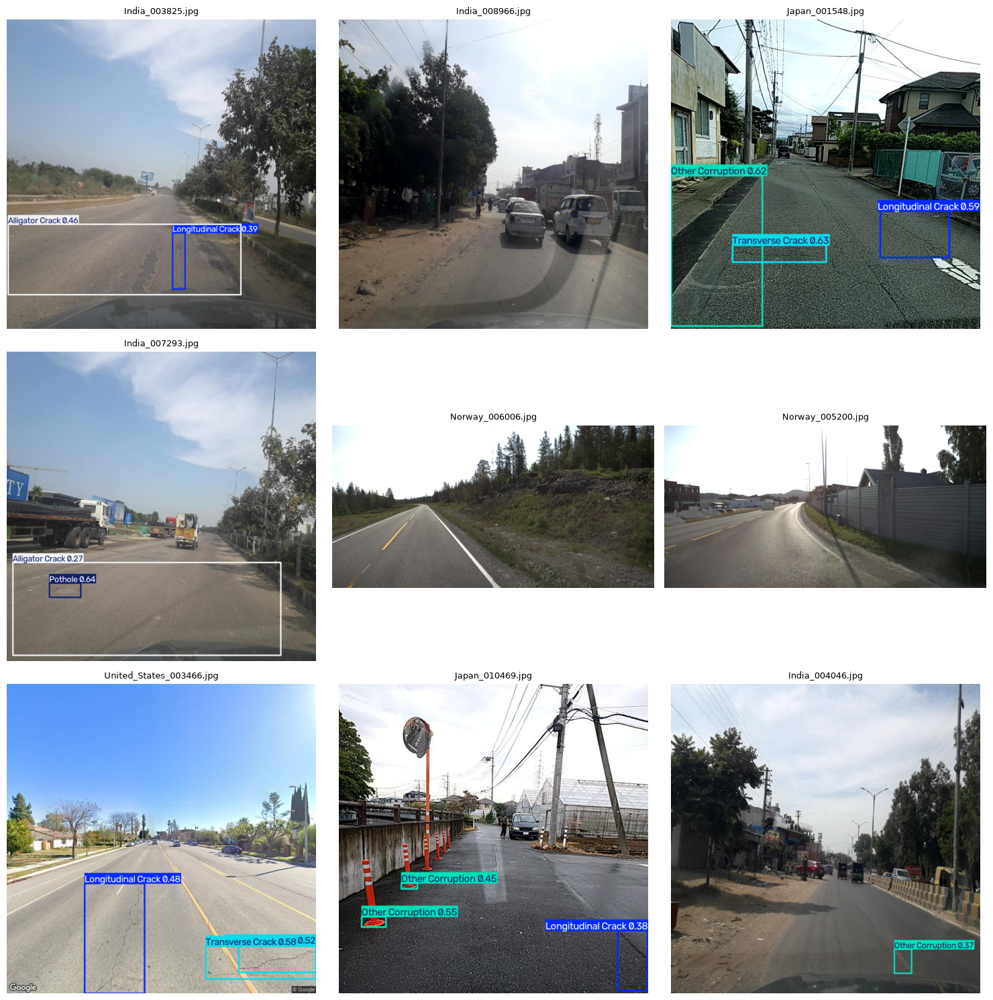

In [62]:
# ==========================================
# Visualize Predictions
# ==========================================

plt.figure(figsize=(15, 15))

for i, result in enumerate(results):

    image = result.plot()

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i + 1)

    plt.imshow(image)

    plt.title(sample_images[i], fontsize=9)

    plt.axis("off")


plt.tight_layout()

plt.show()

# **YOLOv8 Small**

In [63]:
# ==========================================
# Load YOLOv8 Small Model
# ==========================================

model_small = YOLO("yolov8s.pt")

In [65]:
# ==========================================
# Train YOLOv8 Small Model
# ==========================================
PROJECT_ROOT = "/Users/sandrakhyikwa/AI_Tech/Road-damage-detection"
results_small = model_small.train(

    data=f"{PROJECT_ROOT}/notebook/data.yaml",

    epochs=50,

    imgsz=640,

    batch=16,

    patience=20,

    seed=42,

    project=f"{PROJECT_ROOT}/reports/runs/detect",

    name="YOLOv8s",

    exist_ok=True,
    device="mps",
)

Ultralytics 8.4.177 🚀 Python-3.14.0 torch-2.14.1 MPS (Apple M4)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/sandrakhyikwa/AI_Tech/Road-damage-detection/notebook/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLOv8s, nbs=64, nms=None, opset=None,

In [66]:
# ==========================================
# Read Training Results
# ==========================================

results = pd.read_csv(
    "/Users/sandrakhyikwa/AI_Tech/Road-damage-detection/reports/runs/detect/YOLOv8s/results.csv"
)

results

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,441.462,2.12050,3.48696,1.87277,0.16705,0.20771,0.09351,0.03540,2.39264,6.31857,2.08326,0.000369,0.000369,0.000369
1,2,877.473,2.22414,3.01674,1.94755,0.23604,0.16692,0.09369,0.03501,2.46975,4.07043,2.16104,0.000725,0.000725,0.000725
2,3,1306.560,2.22732,3.02220,1.99336,0.48573,0.09949,0.07093,0.02519,2.45313,4.89907,2.23490,0.001066,0.001066,0.001066
3,4,1738.900,2.16057,2.93409,1.95359,0.28205,0.18385,0.14129,0.05259,2.34333,4.20390,2.09785,0.001045,0.001045,0.001045
4,5,2162.670,2.11771,2.80668,1.91770,0.31660,0.21217,0.13235,0.04973,2.21906,3.35156,1.98039,0.001023,0.001023,0.001023
5,6,2570.930,2.06148,2.71120,1.85055,0.28907,0.25014,0.18500,0.07576,2.18286,3.28217,1.89441,0.001001,0.001001,0.001001
6,7,2987.800,2.01087,2.62828,1.81753,0.33249,0.24986,0.21098,0.08937,2.16486,3.13694,1.89815,0.000979,0.000979,0.000979
7,8,3396.470,1.99967,2.56905,1.79501,0.33009,0.27661,0.22256,0.09076,2.10003,2.92623,1.86409,0.000957,0.000957,0.000957
8,9,3804.070,1.97120,2.51088,1.77382,0.33220,0.29488,0.24108,0.09921,2.12811,2.88668,1.87553,0.000935,0.000935,0.000935
9,10,4212.410,1.93123,2.42539,1.73673,0.33945,0.32674,0.24879,0.10603,2.09250,2.71137,1.83875,0.000913,0.000913,0.000913


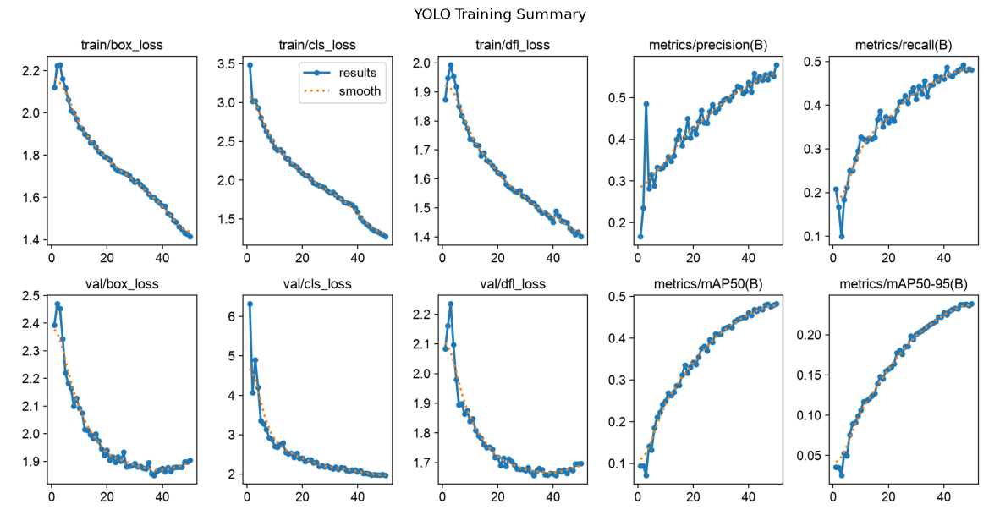

In [67]:
img_path = '/Users/sandrakhyikwa/AI_Tech/Road-damage-detection/reports/runs/detect/YOLOv8s/results.png'
img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(15,8))
plt.imshow(img)
plt.axis("off")
plt.title("YOLO Training Summary")
plt.show()

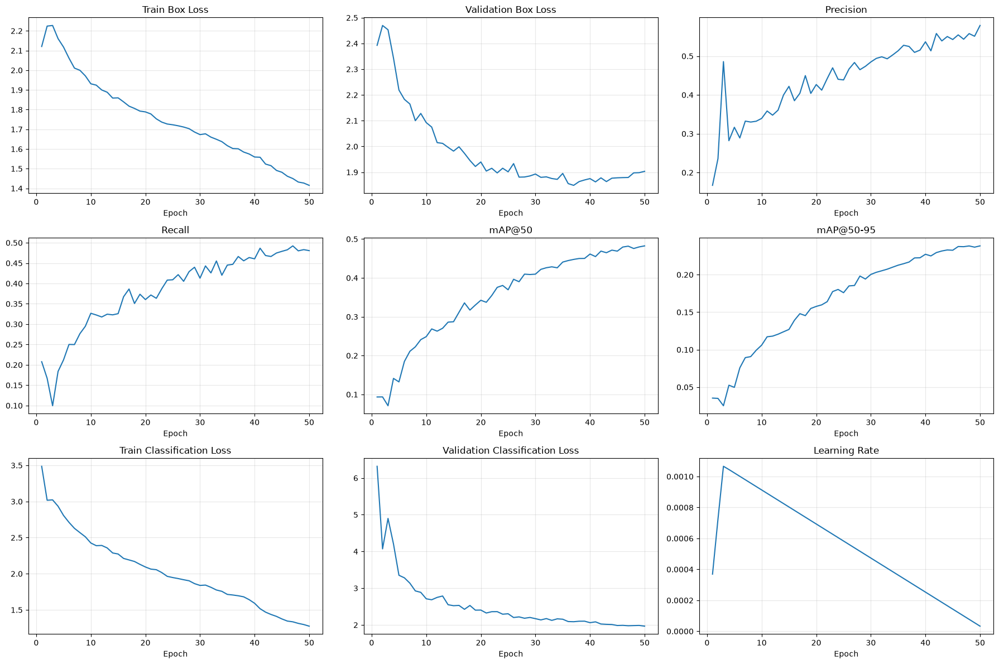

In [68]:
# ==========================================
# Visualize Training Results
# ==========================================

metrics = [

    ("train/box_loss", "Train Box Loss"),

    ("val/box_loss", "Validation Box Loss"),

    ("metrics/precision(B)", "Precision"),

    ("metrics/recall(B)", "Recall"),

    ("metrics/mAP50(B)", "mAP@50"),

    ("metrics/mAP50-95(B)", "mAP@50-95"),

    ("train/cls_loss", "Train Classification Loss"),

    ("val/cls_loss", "Validation Classification Loss"),

    ("lr/pg0", "Learning Rate")

]

plt.figure(figsize=(18, 12))

for i, (column, title) in enumerate(metrics):

    plt.subplot(3, 3, i + 1)

    plt.plot(results["epoch"], results[column])

    plt.title(title)

    plt.xlabel("Epoch")

    plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [69]:
best_model_small = YOLO(
    "/Users/sandrakhyikwa/AI_Tech/Road-damage-detection/reports/runs/detect/YOLOv8s/weights/best.pt"
)

# ==========================================
# Evaluate YOLOv8 small Model
# ==========================================

metrics_small = best_model_small.val(
    data=f"{PROJECT_ROOT}/notebook/data.yaml",
    project=f"{PROJECT_ROOT}/reports/runs/detect",
    split="test"
)

Ultralytics 8.4.177 🚀 Python-3.14.0 torch-2.14.1 CPU (Apple M4)
Model summary (fused): 72 layers, 11,127,519 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.1 ms, read: 581.3±336.3 MB/s, size: 455.1 KB)
val: Scanning /Users/sandrakhyikwa/AI_Tech/Road-damage-detection/data/dataset/RDD_SAMPLE/test/labels.cache... 2000 images, 631 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2000/2000 399.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 1.1it/s 1:510.9ss
                   all       2000       3223      0.552      0.466      0.477      0.235
    Longitudinal Crack        724       1354      0.567      0.455       0.47      0.233
      Transverse Crack        373        575      0.497      0.423      0.408      0.174
       Alligator Crack        397        503      0.605      0.553      0.576      0.276
      Other Corruption        355        509      0.612      0.605      0.623      0.

In [70]:
# ==========================================
# Store Evaluation Metrics
# ==========================================

small_results = {

    "Model": "YOLOv8s",

    "Precision": metrics_small.box.mp,

    "Recall": metrics_small.box.mr,

    "mAP50": metrics_small.box.map50,

    "mAP50-95": metrics_small.box.map,

    "FPS": None,

    "Inference Time (ms)": None,

    "Model Size (MB)": round(
        os.path.getsize(
            f"{PROJECT_ROOT}/reports/runs/detect/YOLOv8s/weights/best.pt"
        ) / (1024 ** 2),
        2
    )

}
small_results

{'Model': 'YOLOv8s',
 'Precision': np.float64(0.5519143806319038),
 'Recall': np.float64(0.4659350379492843),
 'mAP50': np.float64(0.476508799231409),
 'mAP50-95': np.float64(0.2353759365489009),
 'FPS': None,
 'Inference Time (ms)': None,
 'Model Size (MB)': 21.48}

In [71]:
# ==========================================
# Select Random Test Images
# ==========================================

sample_images = np.random.choice(
    os.listdir(TEST_IMAGES),
    9
)

sample_images

array(['India_003825.jpg', 'India_008966.jpg', 'Japan_001548.jpg', 'India_007293.jpg', 'Norway_006006.jpg', 'Norway_005200.jpg', 'United_States_003466.jpg', 'Japan_010469.jpg', 'India_004046.jpg'], dtype='<U26')

In [72]:
sources=[
        os.path.join(TEST_IMAGES, image)
        for image in sample_images]

In [73]:
# ==========================================
# Predict on Test Images
# ==========================================

results = best_model_small.predict(

    source=sources,

    conf=0.25,

    verbose=False
)


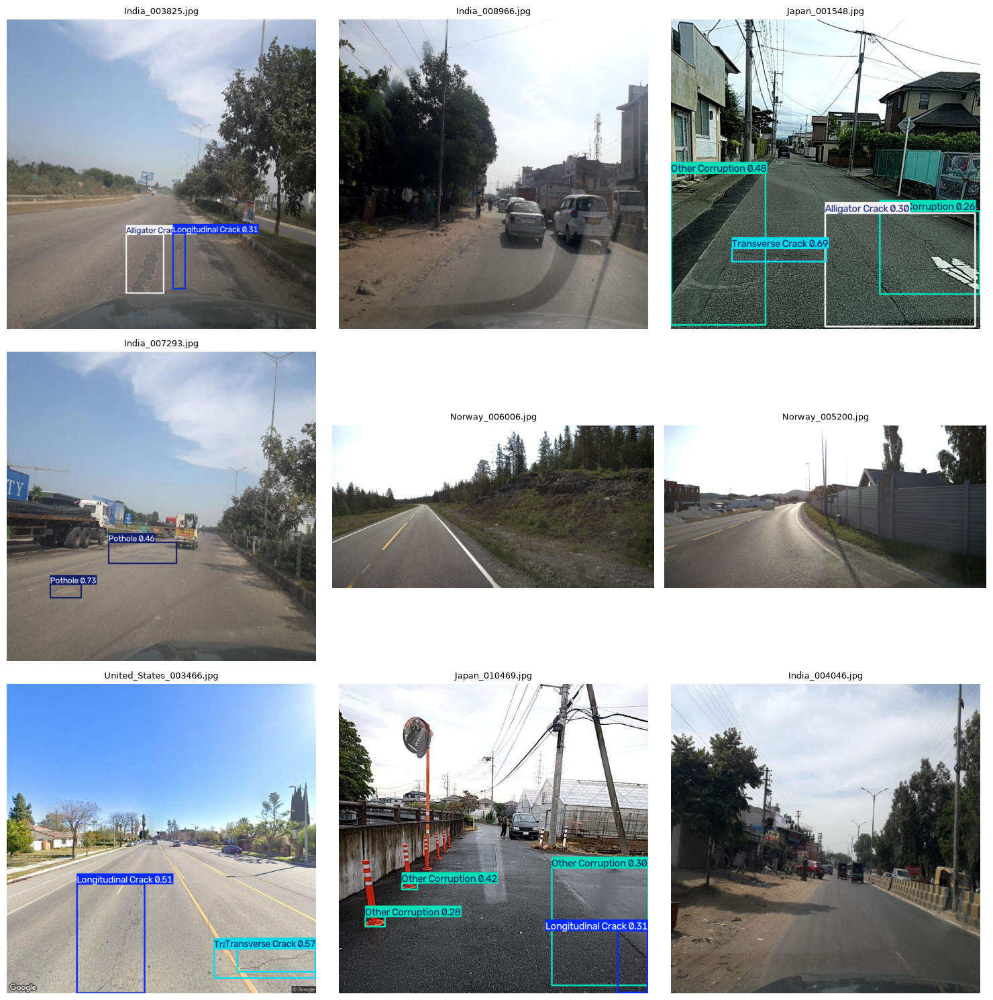

In [74]:
# ==========================================
# Visualize Predictions
# ==========================================

plt.figure(figsize=(15, 15))

for i, result in enumerate(results):

    image = result.plot()

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i + 1)

    plt.imshow(image)

    plt.title(sample_images[i], fontsize=9)

    plt.axis("off")

plt.tight_layout()

plt.show()

# **YOLOv11 Medium**

In [75]:
# ==========================================
# Load YOLOv11 Medium Model
# ==========================================

from ultralytics import YOLO

model_yolo11s = YOLO("yolo11s.pt")

In [76]:
# ==========================================
# Train YOLOv11 Medium Model
# ==========================================
PROJECT_ROOT = "/Users/sandrakhyikwa/AI_Tech/Road-damage-detection"
results_medium = model_yolo11s.train(

    data=f"{PROJECT_ROOT}/notebook/data.yaml",

    epochs=50,

    imgsz=640,

    batch=16,

    patience=20,

    seed=42,

    project=f"{PROJECT_ROOT}/reports/runs/detect",

    name="YOLOv11s",
    
    device="mps",

    exist_ok=True
)

Ultralytics 8.4.177 🚀 Python-3.14.0 torch-2.14.1 MPS (Apple M4)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/sandrakhyikwa/AI_Tech/Road-damage-detection/notebook/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLOv11s, nbs=64, nms=None, opset=None

In [77]:
# ==========================================
# Read Training Results
# ==========================================

results = pd.read_csv(
    "/Users/sandrakhyikwa/AI_Tech/Road-damage-detection/reports/runs/detect/YOLOv11s/results.csv"
)

results

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,462.814,2.21874,3.67523,1.96763,0.49019,0.08128,0.05559,0.02042,2.48928,6.61002,2.14475,0.000369,0.000369,0.000369
1,2,897.530,2.28383,3.08368,2.02561,0.21968,0.15380,0.08001,0.02888,2.49966,3.89490,2.23469,0.000725,0.000725,0.000725
2,3,1341.750,2.28192,3.09622,2.05493,0.10234,0.18542,0.04559,0.01595,2.41292,5.38473,2.19556,0.001066,0.001066,0.001066
3,4,1789.530,2.21410,3.00226,1.98247,0.24886,0.15817,0.12512,0.04768,2.33733,3.63513,2.10429,0.001045,0.001045,0.001045
4,5,2251.910,2.16601,2.85592,1.95071,0.23938,0.22058,0.13406,0.05012,2.28615,3.08454,2.00345,0.001023,0.001023,0.001023
5,6,2695.150,2.10727,2.75662,1.89902,0.21197,0.22142,0.14420,0.05873,2.24657,3.37230,2.01848,0.001001,0.001001,0.001001
6,7,5007.990,2.05631,2.69349,1.85350,0.25870,0.25143,0.17604,0.07156,2.19561,3.25932,1.95503,0.000979,0.000979,0.000979
7,8,7332.190,2.03482,2.63376,1.83412,0.29911,0.24046,0.19605,0.07610,2.19587,2.97988,1.92908,0.000957,0.000957,0.000957
8,9,7983.640,2.00877,2.58495,1.81907,0.34010,0.27715,0.22388,0.09215,2.12653,2.91408,1.88874,0.000935,0.000935,0.000935
9,10,8454.840,1.96775,2.49561,1.76428,0.36811,0.27553,0.23844,0.09617,2.12599,2.88891,1.92144,0.000913,0.000913,0.000913


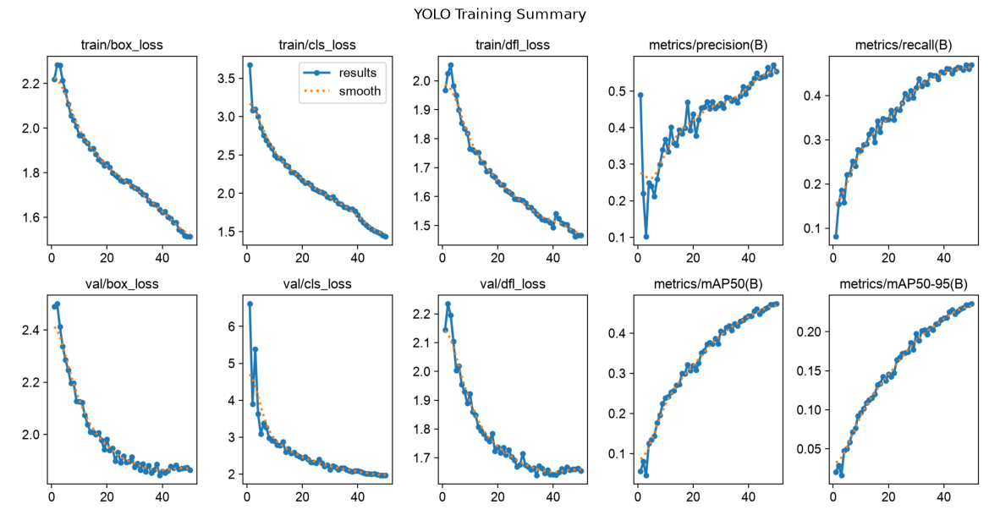

In [78]:
img_path = '/Users/sandrakhyikwa/AI_Tech/Road-damage-detection/reports/runs/detect/YOLOv11s/results.png'
img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(15,8))
plt.imshow(img)
plt.axis("off")
plt.title("YOLO Training Summary")
plt.show()

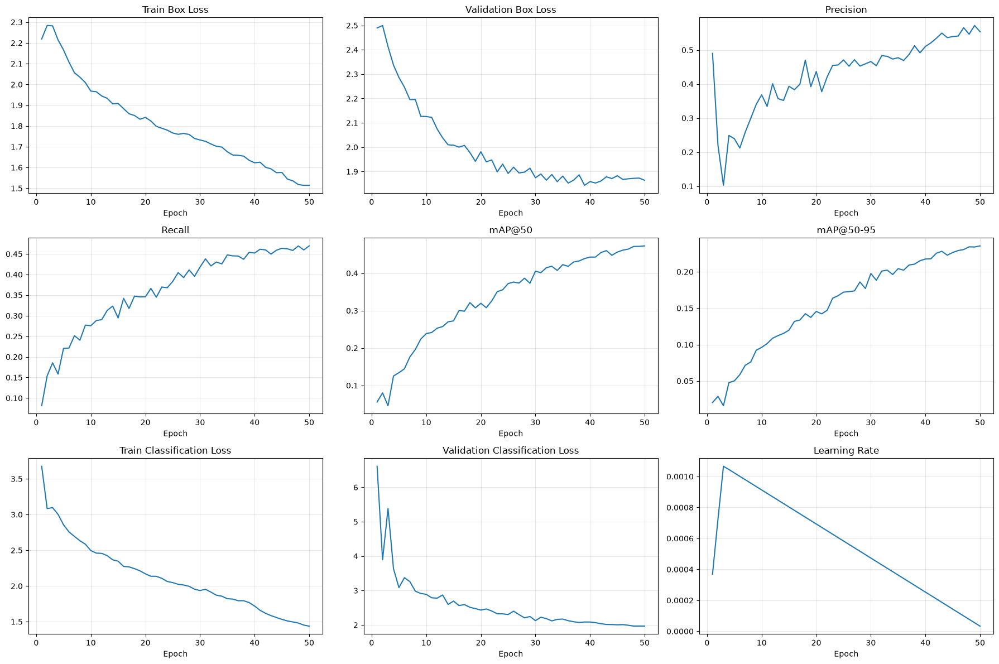

In [79]:
# ==========================================
# Visualize Training Results
# ==========================================

metrics = [

    ("train/box_loss", "Train Box Loss"),

    ("val/box_loss", "Validation Box Loss"),

    ("metrics/precision(B)", "Precision"),

    ("metrics/recall(B)", "Recall"),

    ("metrics/mAP50(B)", "mAP@50"),

    ("metrics/mAP50-95(B)", "mAP@50-95"),

    ("train/cls_loss", "Train Classification Loss"),

    ("val/cls_loss", "Validation Classification Loss"),

    ("lr/pg0", "Learning Rate")

]


plt.figure(figsize=(18, 12))

for i, (column, title) in enumerate(metrics):

    plt.subplot(3, 3, i + 1)

    plt.plot(results["epoch"], results[column])

    plt.title(title)

    plt.xlabel("Epoch")

    plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [80]:
# ==========================================
# Load Best YOLOv8 Medium Model
# ==========================================

best_model_medium = YOLO(
    "/Users/sandrakhyikwa/AI_Tech/Road-damage-detection/reports/runs/detect/YOLOv11s/weights/best.pt"
)

In [81]:
# ==========================================
# Evaluate YOLOv11 Medium
# ==========================================
PROJECT_ROOT = "/Users/sandrakhyikwa/AI_Tech/Road-damage-detection"
metrics_medium = best_model_medium.val(

    data=f"{PROJECT_ROOT}/notebook/data.yaml",
    
    project=f"{PROJECT_ROOT}/reports/runs/detect",

    split="test",

    verbose=False

)

Ultralytics 8.4.177 🚀 Python-3.14.0 torch-2.14.1 CPU (Apple M4)
YOLO11s summary (fused): 100 layers, 9,414,735 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.0 ms, read: 927.5±681.8 MB/s, size: 455.1 KB)
val: Scanning /Users/sandrakhyikwa/AI_Tech/Road-damage-detection/data/dataset/RDD_SAMPLE/test/labels.cache... 2000 images, 631 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2000/2000 466.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 1.3it/s 1:330.7ss
                   all       2000       3223      0.522      0.472      0.461      0.224
Speed: 0.2ms preprocess, 41.2ms inference, 0.0ms loss, 0.1ms postprocess per image
Results saved to /Users/sandrakhyikwa/AI_Tech/Road-damage-detection/reports/runs/detect/val-3


In [82]:
# ==========================================
# Store Evaluation Metrics
# ==========================================

medium_results = {

    "Model": "YOLOv11s",

    "Precision": metrics_medium.box.mp,

    "Recall": metrics_medium.box.mr,

    "mAP50": metrics_medium.box.map50,

    "mAP50-95": metrics_medium.box.map,

    "FPS": None,

    "Inference Time (ms)": None,

    "Model Size (MB)": round(
        os.path.getsize(
            f"{PROJECT_ROOT}/reports/runs/detect/YOLOv11s/weights/best.pt"
        ) / (1024 ** 2),
        2
    )

}
medium_results

{'Model': 'YOLOv11s',
 'Precision': np.float64(0.5218735171137314),
 'Recall': np.float64(0.47155279218706647),
 'mAP50': np.float64(0.4609631410627558),
 'mAP50-95': np.float64(0.2239124359023905),
 'FPS': None,
 'Inference Time (ms)': None,
 'Model Size (MB)': 18.29}

In [83]:
# ==========================================
# Select Random Test Images
# ==========================================

sample_images = np.random.choice(
    os.listdir(TEST_IMAGES),
    9
)

sample_images

array(['India_003825.jpg', 'India_008966.jpg', 'Japan_001548.jpg', 'India_007293.jpg', 'Norway_006006.jpg', 'Norway_005200.jpg', 'United_States_003466.jpg', 'Japan_010469.jpg', 'India_004046.jpg'], dtype='<U26')

In [84]:
sources=[
        os.path.join(TEST_IMAGES, image)
        for image in sample_images]

In [85]:
# ==========================================
# Predict on Test Images
# ==========================================

results = best_model_medium.predict(

    source=sources,

    conf=0.25,

    verbose=False
)


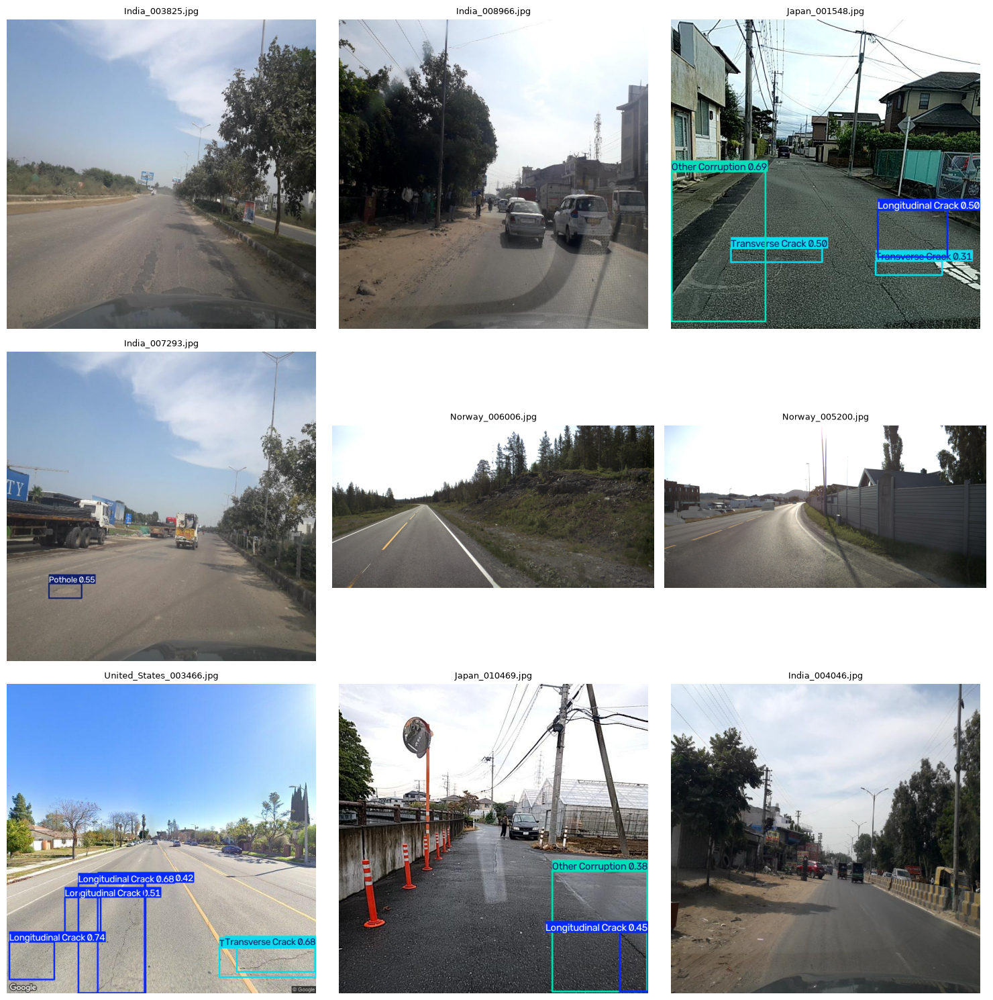

In [86]:
# ==========================================
# Visualize Predictions
# ==========================================

plt.figure(figsize=(15, 15))

for i, result in enumerate(results):

    image = result.plot()

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i + 1)

    plt.imshow(image)

    plt.title(sample_images[i], fontsize=9)

    plt.axis("off")

plt.tight_layout()

plt.show()

# **Comparison between three models**

In [87]:
# ==========================================
# Select Images for Speed Benchmark
# ==========================================

np.random.seed(42)

benchmark_images = np.random.choice(
    os.listdir(TEST_IMAGES),
    100,
    replace=False
)

benchmark_paths = [
    os.path.join(TEST_IMAGES, img)
    for img in benchmark_images
]

In [88]:
# ==========================================
# Measure Inference Speed
# ==========================================

import time

def measure_inference_speed(model, image_paths, runs=5):

    # Warm-up
    model.predict(
        source=image_paths[:5],
        verbose=False
    )

    times = []

    for _ in range(runs):

        start = time.perf_counter()

        model.predict(
            source=image_paths,
            verbose=False
        )

        end = time.perf_counter()

        times.append(end - start)

    average_time = sum(times) / len(times)

    inference_time_ms = (
        average_time / len(image_paths)
    ) * 1000

    fps = 1000 / inference_time_ms

    return round(inference_time_ms, 2), round(fps, 2)

In [89]:
nano_time, nano_fps = measure_inference_speed(
    best_model_nano,
    benchmark_paths
)

nano_results["Inference Time (ms)"] = nano_time
nano_results["FPS"] = nano_fps

In [90]:
small_time, small_fps = measure_inference_speed(
    best_model_small,
    benchmark_paths
)

small_results["Inference Time (ms)"] = small_time
small_results["FPS"] = small_fps

In [91]:
medium_time, medium_fps = measure_inference_speed(
    best_model_medium,
    benchmark_paths
)

medium_results["Inference Time (ms)"] = medium_time
medium_results["FPS"] = medium_fps

In [92]:
# Create Comparison DataFrame
# ==========================================

comparison_df = pd.DataFrame([

    nano_results,

    small_results,

    medium_results

])

comparison_df = comparison_df.round(4)

comparison_df

,Model,Precision,Recall,mAP50,mAP50-95,FPS,Inference Time (ms),Model Size (MB)
0,YOLOv8n,0.5164,0.4548,0.4526,0.2198,20.61,48.52,6.21
1,YOLOv8s,0.5519,0.4659,0.4765,0.2354,12.07,82.83,21.48
2,YOLOv11s,0.5219,0.4716,0.4610,0.2239,12.50,80.02,18.29


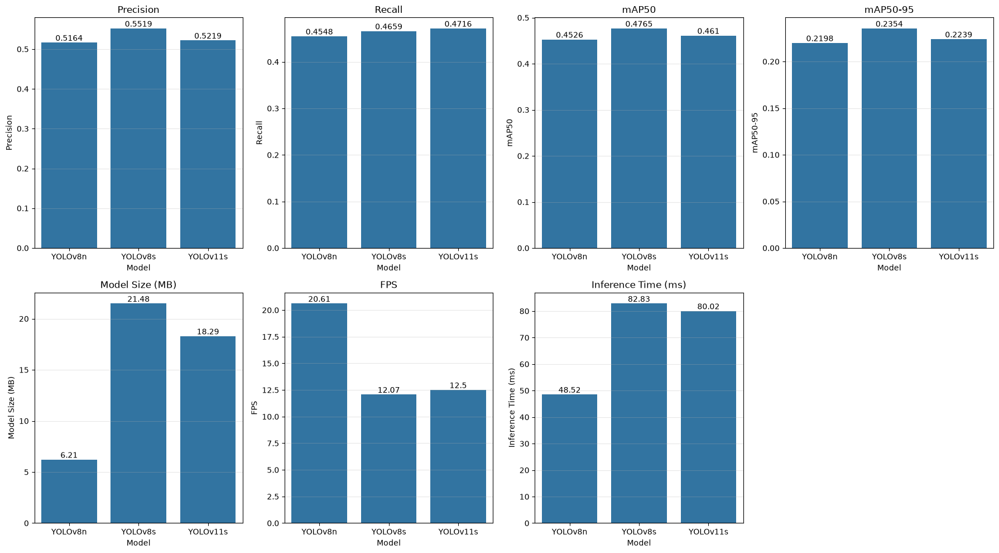

In [93]:
# ==========================================
# Models Comparison Dashboard
# ==========================================

metrics = [

    ("Precision", "Precision"),

    ("Recall", "Recall"),

    ("mAP50", "mAP50"),

    ("mAP50-95", "mAP50-95"),

    ("Model Size (MB)", "Model Size (MB)"),

    ("FPS", "FPS"),

    ('Inference Time (ms)','Inference Time (ms)')

]

plt.figure(figsize=(18, 10))

for i, (column, title) in enumerate(metrics):

    plt.subplot(2, 4, i + 1)

    g = sns.barplot(x = comparison_df["Model"], y = comparison_df[column])
    for i in g.containers:
        g.bar_label(i)

    plt.title(title)

    plt.xlabel("Model")

    plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()